# Exploratory Data Analysis (EDA) - Complete Assignment Solutions\nThis notebook contains complete Python solutions for all 4 EDA assignments.

---\n# EDA - 1: Bike Details Dataset

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df_bikes = pd.read_csv('/content/bike_details.csv')
print("Bike details loaded successfully! Shape:", df_bikes.shape)
display(df_bikes.head())

Bike details loaded successfully! Shape: (1061, 7)


,name,selling_price,year,seller_type,owner,km_driven,ex_showroom_price
0,Royal Enfield Classic 350,175000,2019,Individual,1st owner,350,NaN
1,Honda Dio,45000,2017,Individual,1st owner,5650,NaN
2,Royal Enfield Classic Gunmetal Grey,150000,2018,Individual,1st owner,12000,148114.0
3,Yamaha Fazer FI V 2.0 [2016-2018],65000,2015,Individual,1st owner,23000,89643.0
4,Yamaha SZ [2013-2014],20000,2011,Individual,2nd owner,21000,NaN


### Q1. What is the range of selling prices in the dataset?

In [10]:
min_price = df_bikes['selling_price'].min()
max_price = df_bikes['selling_price'].max()
print(f"Range of selling prices: ₹{min_price:,} to ₹{max_price:,} (Difference: ₹{max_price - min_price:,})")

Range of selling prices: ₹5,000 to ₹760,000 (Difference: ₹755,000)


### Q2. What is the median selling price for bikes in the dataset?

In [11]:
median_price = df_bikes['selling_price'].median()
print(f"Median selling price: ₹{median_price:,}")

Median selling price: ₹45,000.0


### Q3. What is the most common seller type?

In [12]:
common_seller = df_bikes['seller_type'].mode()[0]
print(f"The most common seller type is: {common_seller}")

The most common seller type is: Individual


### Q4. How many bikes have driven more than 50,000 kilometers?

In [13]:
count_gt_50k = (df_bikes['km_driven'] > 50000).sum()
print(f"Number of bikes driven > 50,000 km: {count_gt_50k}")

Number of bikes driven > 50,000 km: 170


### Q5. What is the average km_driven value for each ownership type?

In [14]:
avg_km_owner = df_bikes.groupby('owner')['km_driven'].mean().reset_index()
print(avg_km_owner)

       owner      km_driven
0  1st owner   32816.583333
1  2nd owner   39288.991870
2  3rd owner   33292.181818
3  4th owner  311500.000000


### Q6. What proportion of bikes are from the year 2015 or older?

In [15]:
prop_2015_older = (df_bikes['year'] <= 2015).mean()
print(f"Proportion of bikes from 2015 or older: {prop_2015_older:.2%}")

Proportion of bikes from 2015 or older: 56.64%


### Q7. What is the trend of missing values across the dataset?

Missing values per column:
 ex_showroom_price    435
dtype: int64


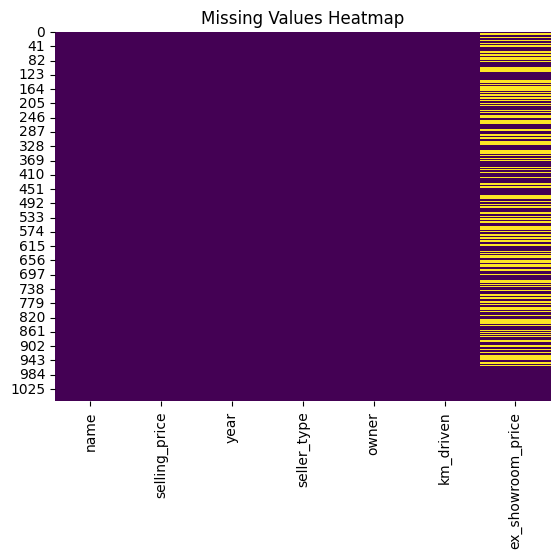

In [16]:
missing_values = df_bikes.isnull().sum()
print("Missing values per column:\n", missing_values[missing_values > 0])
sns.heatmap(df_bikes.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

### Q8. What is the highest ex_showroom_price recorded, and for which bike?

In [17]:
max_ex_showroom = df_bikes['ex_showroom_price'].max()
bike_max_price = df_bikes.loc[df_bikes['ex_showroom_price'] == max_ex_showroom, ['name', 'ex_showroom_price']]
print(bike_max_price)

                           name  ex_showroom_price
134  Harley-Davidson Street Bob          1278000.0


### Q9. What is the total number of bikes listed by each seller type?

In [18]:
seller_counts = df_bikes['seller_type'].value_counts()
print(seller_counts)

seller_type
Individual    1055
Dealer           6
Name: count, dtype: int64


### Q10. What is the relationship between selling_price and km_driven for first-owner bikes?

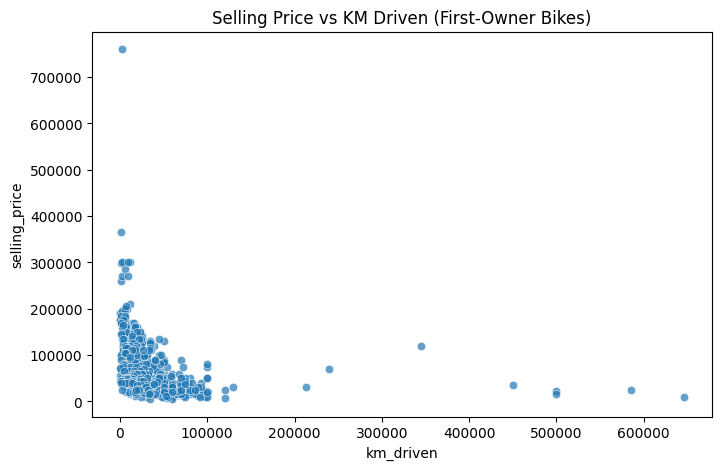

In [19]:
first_owner_df = df_bikes[df_bikes['owner'] == '1st owner']
plt.figure(figsize=(8, 5))
sns.scatterplot(data=first_owner_df, x='km_driven', y='selling_price', alpha=0.7)
plt.title('Selling Price vs KM Driven (First-Owner Bikes)')
plt.show()

### Q11. Identify and remove outliers in the km_driven column using the IQR method.

In [20]:
Q1 = df_bikes['km_driven'].quantile(0.25)
Q3 = df_bikes['km_driven'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_bikes_filtered = df_bikes[(df_bikes['km_driven'] >= lower_bound) & (df_bikes['km_driven'] <= upper_bound)]
print(f"Original rows: {len(df_bikes)}, Rows after removing outliers: {len(df_bikes_filtered)}")

Original rows: 1061, Rows after removing outliers: 1022


### Q12. Perform a bivariate analysis to visualize the relationship between year and selling_price.

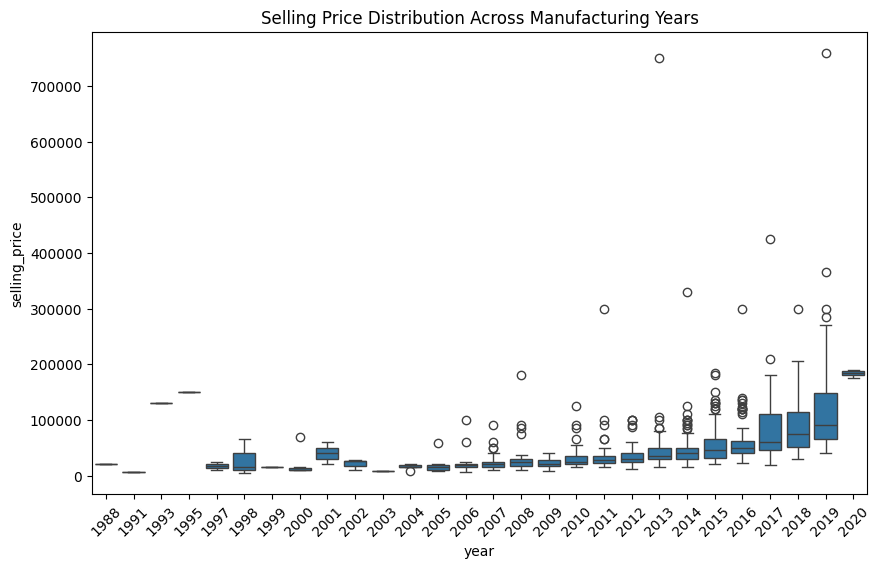

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_bikes, x='year', y='selling_price')
plt.title('Selling Price Distribution Across Manufacturing Years')
plt.xticks(rotation=45)
plt.show()

### Q13. What is the average depreciation in selling price based on the bike's age?

In [22]:
current_year = 2026
df_bikes['age'] = current_year - df_bikes['year']
depreciation = df_bikes.groupby('age')['selling_price'].mean().reset_index()
print(depreciation)

    age  selling_price
0     6  183333.333333
1     7  119689.511628
2     8   87660.374046
3     9   78894.736842
4    10   58469.018692
5    11   56500.000000
6    12   48668.131868
7    13   51136.986301
8    14   35748.400000
9    15   35655.721311
10   16   31793.333333
11   17   22267.857143
12   18   34289.285714
13   19   24927.586207
14   20   23380.000000
15   21   16978.571429
16   22   15100.000000
17   23    8000.000000
18   24   20666.666667
19   25   40000.000000
20   26   20833.333333
21   27   15000.000000
22   28   28333.333333
23   29   17500.000000
24   31  150000.000000
25   33  130000.000000
26   35    6000.000000
27   38   20000.000000


### Q14. Which bike names are priced significantly above the average price for their manufacturing year?

In [23]:
df_bikes['mean_year_price'] = df_bikes.groupby('year')['selling_price'].transform('mean')
df_bikes['std_year_price'] = df_bikes.groupby('year')['selling_price'].transform('std')
above_avg_bikes = df_bikes[df_bikes['selling_price'] > (df_bikes['mean_year_price'] + 2 * df_bikes['std_year_price'])]
print(above_avg_bikes[['name', 'year', 'selling_price']])

                                     name  year  selling_price
7    Royal Enfield Bullet 350 [2007-2011]  2008         180000
13                          Yamaha YZF R3  2019         365000
52              Royal Enfield Electra 5 S  2010          90000
134            Harley-Davidson Street Bob  2013         750000
137          KTM 390 Duke ABS [2013-2016]  2015         130000
161    Royal Enfield Classic Desert Storm  2012         100000
208              Royal Enfield Bullet 500  2015         130000
224  Royal Enfield Bullet 350 [2007-2011]  2007          90000
242                            KTM RC 390  2017         210000
286    Royal Enfield Classic Desert Storm  2015         130000
289        Kawasaki Ninja 650 [2018-2019]  2017         425000
291                   Kawasaki Ninja 250R  2010         125000
295                       Suzuki GSX S750  2019         760000
306                             Yamaha Rx  2000          70000
311            Harley-Davidson Street 750  2014        

### Q15. Develop a correlation matrix for numeric columns and visualize it using a heatmap.

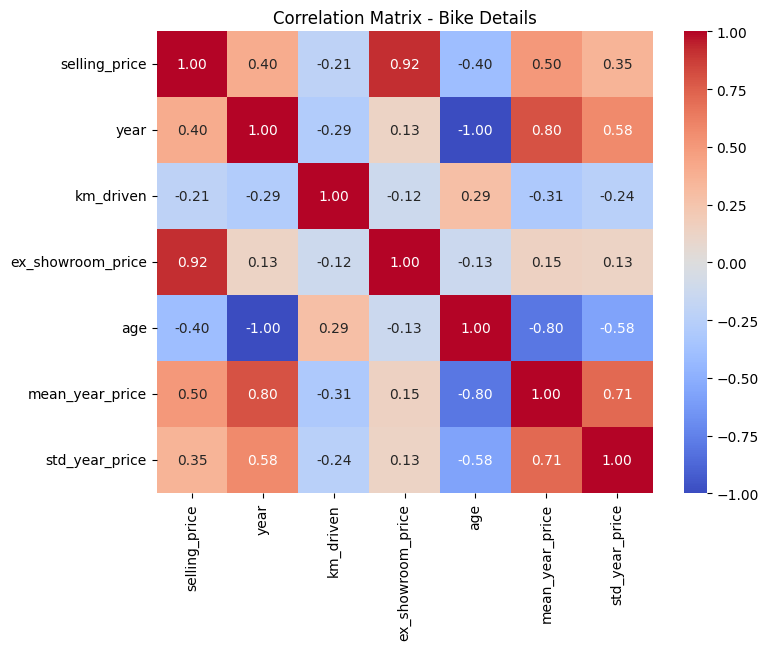

In [24]:
plt.figure(figsize=(8, 6))
numeric_cols = df_bikes.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix - Bike Details')
plt.show()

---\n# EDA - 2: Car Sales Dataset

In [25]:
# Load dataset
df_cars = pd.read_csv('/content/Car Sale.csv')

### Q1. What is the average selling price of cars for each dealer, and how does it compare across different dealers?

In [26]:
avg_price_dealer = df_cars.groupby('Dealer_Name')['Price ($)'].mean().reset_index()
print(avg_price_dealer)

                                        Dealer_Name     Price ($)
0               Buddy Storbeck's Diesel Service Inc  27217.261563
1                                  C & M Motors Inc  28111.755200
2                                       Capitol KIA  28189.703822
3                                 Chrysler Plymouth  27555.526400
4                            Chrysler of Tri-Cities  28123.091054
5                                     Classic Chevy  28602.014446
6                           Clay Johnson Auto Sales  27816.027113
7                                Diehl Motor CO Inc  27993.929487
8                             Enterprise Rent A Car  28312.580800
9                        Gartner Buick Hyundai Saab  28247.621019
10                              Hatfield Volkswagen  27853.712242
11                                  Iceberg Rentals  28522.958533
12                     McKinney Dodge Chrysler Jeep  27684.096979
13                      Motor Vehicle Branch Office  27956.739617
14        

### Q2. Which car brand (Company) has the highest variation in prices, and what does this tell us about pricing trends?

In [27]:
brand_std = df_cars.groupby('Company')['Price ($)'].std().reset_index()
highest_variation_brand = brand_std.loc[brand_std['Price ($)'].idxmax()]
print('Brand with highest price variation:', highest_variation_brand)

Brand with highest price variation: Company           Lincoln
Price ($)    19658.050211
Name: 15, dtype: object


### Q3. What is the distribution of car prices for each transmission type, and how do the interquartile ranges compare?

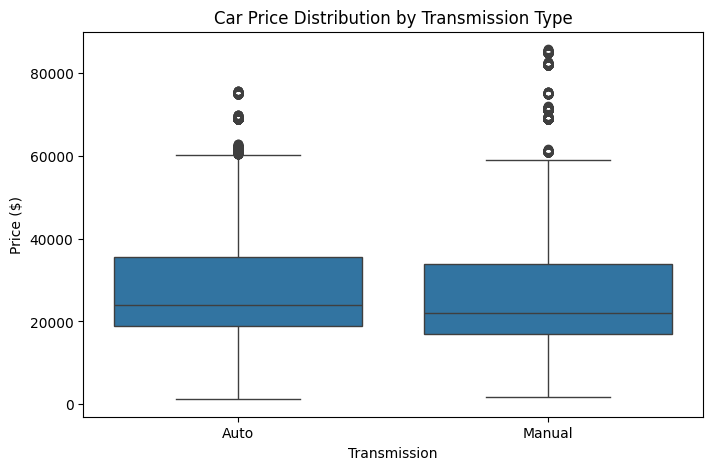

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_cars, x='Transmission', y='Price ($)')
plt.title('Car Price Distribution by Transmission Type')
plt.show()

### Q4 & Q7. What is the distribution of car prices across different regions, and how does the number of cars sold vary by region?

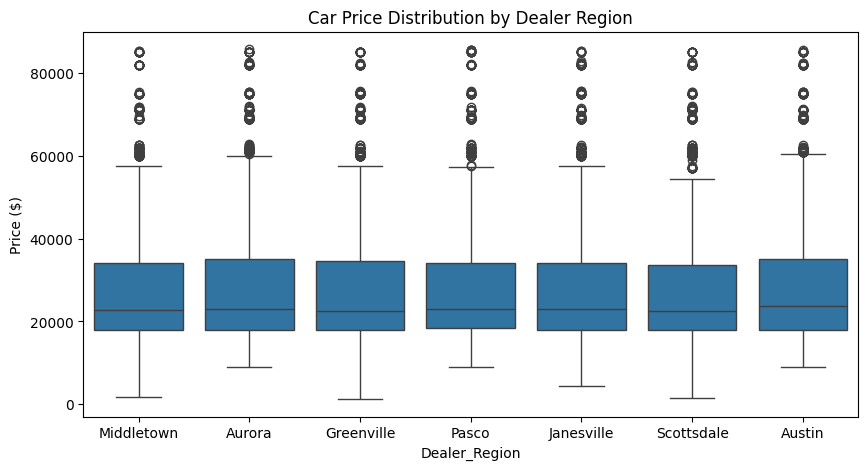

Cars sold by region:
 Dealer_Region
Austin        4135
Janesville    3821
Scottsdale    3433
Pasco         3131
Aurora        3130
Greenville    3128
Middletown    3128
Name: count, dtype: int64


In [29]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_cars, x='Dealer_Region', y='Price ($)')
plt.title('Car Price Distribution by Dealer Region')
plt.show()

region_sales = df_cars['Dealer_Region'].value_counts()
print('Cars sold by region:\n', region_sales)

### Q5. What is the distribution of cars based on body styles?

In [30]:
body_style_counts = df_cars['Body Style'].value_counts()
print(body_style_counts)

Body Style
SUV          6374
Hatchback    6128
Sedan        4488
Passenger    3945
Hardtop      2971
Name: count, dtype: int64


### Q6. How does the average selling price of cars vary by customer gender and annual income?

In [31]:
gender_income_price = df_cars.groupby('Gender').agg({'Annual Income': 'mean', 'Price ($)': 'mean'}).reset_index()
print(gender_income_price)

   Gender  Annual Income     Price ($)
0  Female  755973.021339  28277.265270
1    Male  851184.044207  28039.429407


### Q8. How does the average car price differ between cars with different engine sizes?

In [32]:
avg_price_engine = df_cars.groupby('Engine')['Price ($)'].mean().reset_index()
print(avg_price_engine)

                      Engine     Price ($)
0  DoubleÂ Overhead Camshaft  28248.525972
1          Overhead Camshaft  27914.710631


### Q9. How do car prices vary based on the customer's annual income bracket?

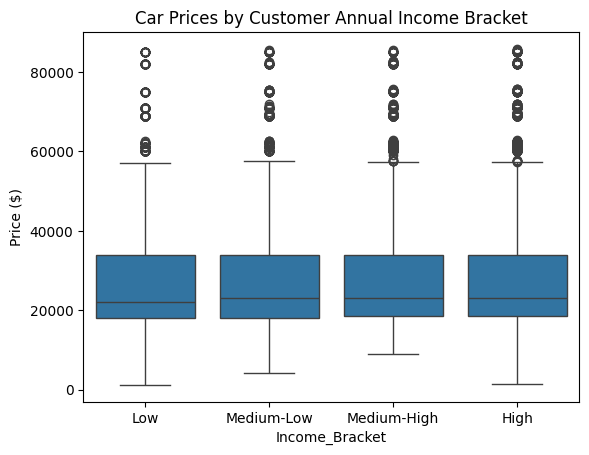

In [33]:
df_cars['Income_Bracket'] = pd.qcut(df_cars['Annual Income'], q=4, labels=['Low', 'Medium-Low', 'Medium-High', 'High'])
sns.boxplot(data=df_cars, x='Income_Bracket', y='Price ($)')
plt.title('Car Prices by Customer Annual Income Bracket')
plt.show()

### Q10. What are the top 5 car models with the highest number of sales, and how does their price distribution look?

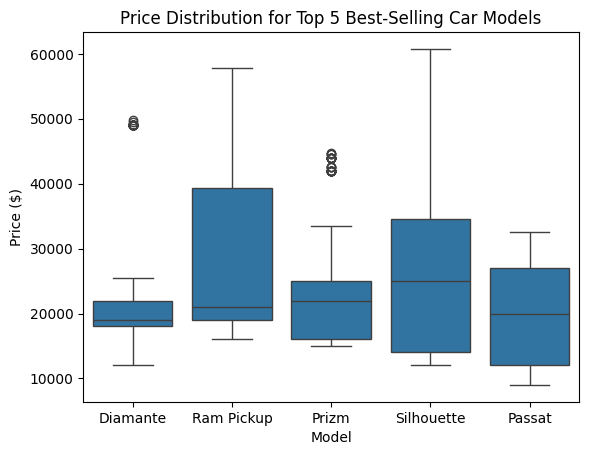

In [34]:
top_models = df_cars['Model'].value_counts().head(5).index
filtered_models = df_cars[df_cars['Model'].isin(top_models)]
sns.boxplot(data=filtered_models, x='Model', y='Price ($)')
plt.title('Price Distribution for Top 5 Best-Selling Car Models')
plt.show()

### Q11. How does car price vary with engine size across different car colors, and which colors have the highest price variation?

In [35]:
color_price_var = df_cars.groupby('Color')['Price ($)'].std().reset_index()
print(color_price_var.sort_values(by='Price ($)', ascending=False))

        Color     Price ($)
2         Red  15519.360962
0       Black  15286.065976
1  Pale White  14077.346859


### Q12. Is there any seasonal trend in car sales based on the date of sale?

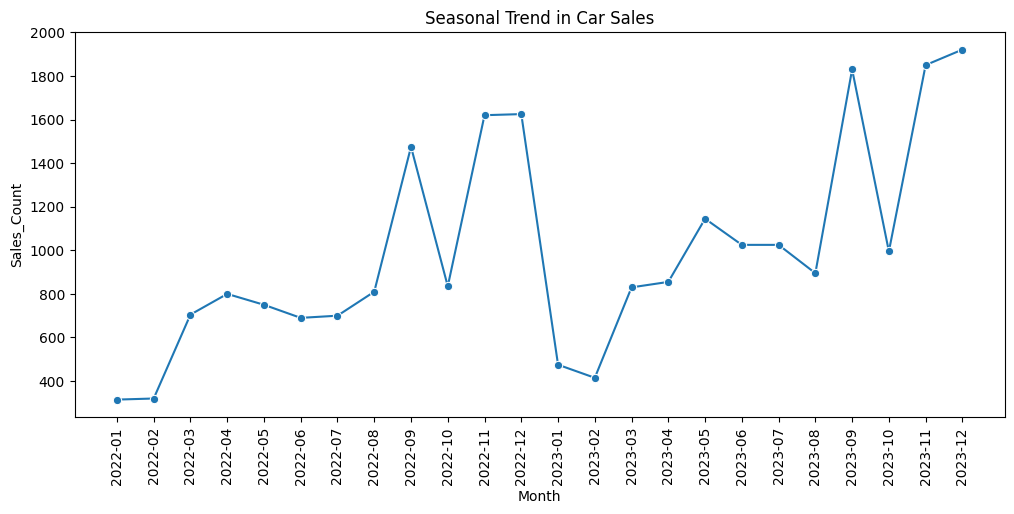

In [36]:
df_cars['Date'] = pd.to_datetime(df_cars['Date'])
df_cars['Month'] = df_cars['Date'].dt.to_period('M')
monthly_sales = df_cars.groupby('Month').size().reset_index(name='Sales_Count')
monthly_sales['Month'] = monthly_sales['Month'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='Month', y='Sales_Count', marker='o')
plt.xticks(rotation=90)
plt.title('Seasonal Trend in Car Sales')
plt.show()

### Q13. How does the car price distribution change when considering different combinations of body style and transmission type?

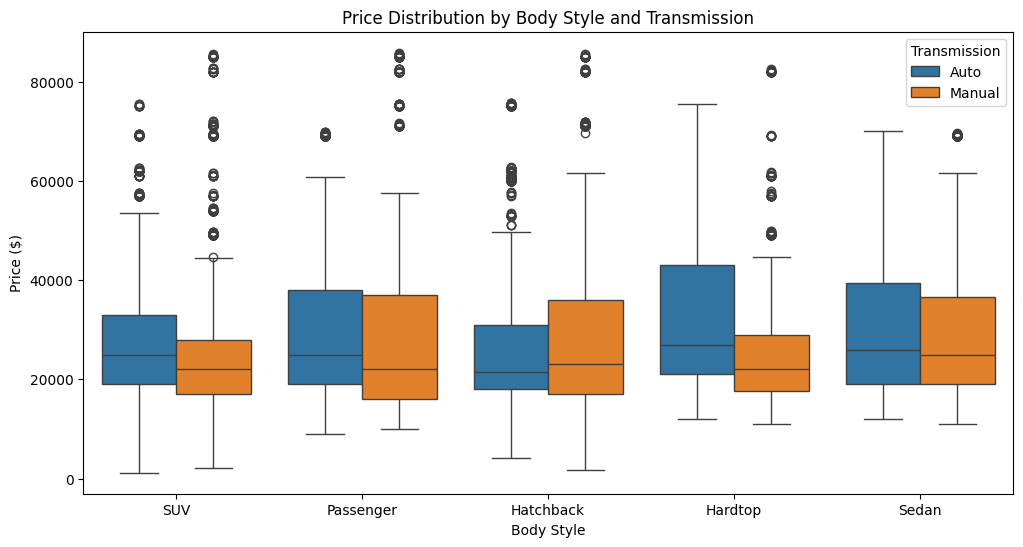

In [37]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_cars, x='Body Style', y='Price ($)', hue='Transmission')
plt.title('Price Distribution by Body Style and Transmission')
plt.show()

### Q14. What is the correlation between car price, engine size, and annual income of customers?

In [38]:
numeric_car_cols = df_cars[['Price ($)', 'Annual Income']]
print(numeric_car_cols.corr())

               Price ($)  Annual Income
Price ($)       1.000000       0.012065
Annual Income   0.012065       1.000000


### Q15. How does the average car price vary across different car models and engine types?

In [60]:
print(df_cars.groupby(['Model', 'Engine'])['Price ($)'].mean())

Model     Engine                   
3-Sep     DoubleÂ Overhead Camshaft    37986.380117
3000GT    DoubleÂ Overhead Camshaft    22764.326923
          Overhead Camshaft            21770.659864
300M      DoubleÂ Overhead Camshaft    21394.888889
323i      DoubleÂ Overhead Camshaft    16744.632287
                                           ...     
Windstar  Overhead Camshaft            17100.272727
Wrangler  DoubleÂ Overhead Camshaft    21145.294737
          Overhead Camshaft            18742.942029
Xterra    DoubleÂ Overhead Camshaft    15940.459459
          Overhead Camshaft            31072.500000
Name: Price ($), Length: 261, dtype: float64


# **3rd data set**

In [39]:
# Load dataset
df_amazon = pd.read_csv('/content/amazon.csv')

In [40]:
avg_price_model_engine = df_cars.groupby(['Model', 'Engine'])['Price ($)'].mean().reset_index()
print(avg_price_model_engine.head(10))

     Model                     Engine     Price ($)
0    3-Sep  DoubleÂ Overhead Camshaft  37986.380117
1   3000GT  DoubleÂ Overhead Camshaft  22764.326923
2   3000GT          Overhead Camshaft  21770.659864
3     300M  DoubleÂ Overhead Camshaft  21394.888889
4     323i  DoubleÂ Overhead Camshaft  16744.632287
5     323i          Overhead Camshaft  21038.162162
6     328i  DoubleÂ Overhead Camshaft  21069.149606
7     328i          Overhead Camshaft  38676.177215
8  4Runner  DoubleÂ Overhead Camshaft  32167.794118
9  4Runner          Overhead Camshaft  25075.416667


### Q1. What is the average rating for each product category?

In [41]:
df_amazon['rating'] = pd.to_numeric(df_amazon['rating'], errors='coerce')
avg_rating_cat = df_amazon.groupby('category')['rating'].mean().reset_index()
print(avg_rating_cat)

                                              category    rating
0    Car&Motorbike|CarAccessories|InteriorAccessori...  3.800000
1    Computers&Accessories|Accessories&Peripherals|...  4.150000
2    Computers&Accessories|Accessories&Peripherals|...  3.500000
3    Computers&Accessories|Accessories&Peripherals|...  3.600000
4    Computers&Accessories|Accessories&Peripherals|...  4.050000
..                                                 ...       ...
206  OfficeProducts|OfficePaperProducts|Paper|Stati...  4.250000
207  OfficeProducts|OfficePaperProducts|Paper|Stati...  4.150000
208  OfficeProducts|OfficePaperProducts|Paper|Stati...  4.300000
209  OfficeProducts|OfficePaperProducts|Paper|Stati...  4.133333
210  Toys&Games|Arts&Crafts|Drawing&PaintingSupplie...  4.300000

[211 rows x 2 columns]


### Q2. What are the top rating_count products by category?

In [42]:
df_amazon['rating_count'] = df_amazon['rating_count'].str.replace(',', '').astype(float)
top_rated_count = df_amazon.sort_values(by='rating_count', ascending=False).groupby('category').head(1)
print(top_rated_count[['category', 'product_name', 'rating_count']])

                                               category  \
47    Electronics|HomeTheater,TV&Video|Accessories|C...   
400   Electronics|Headphones,Earbuds&Accessories|Hea...   
371   Electronics|Mobiles&Accessories|Smartphones&Ba...   
1028  Home&Kitchen|Kitchen&Dining|KitchenTools|Manua...   
588   Computers&Accessories|ExternalDevices&DataStor...   
...                                                 ...   
863   Computers&Accessories|Components|InternalHardD...   
1014   Computers&Accessories|Laptops|TraditionalLaptops   
557   Electronics|Mobiles&Accessories|MobileAccessor...   
269        Electronics|HomeAudio|Speakers|TowerSpeakers   
264   Electronics|HomeAudio|MediaStreamingDevices|St...   

                                           product_name  rating_count  
47    Amazon Basics High-Speed HDMI Cable, 6 Feet - ...      426973.0  
400   boAt Bassheads 100 in Ear Wired Earphones with...      363713.0  
371   Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...      313836.0  
102

### Q3. What is the distribution of discounted prices vs. actual prices?

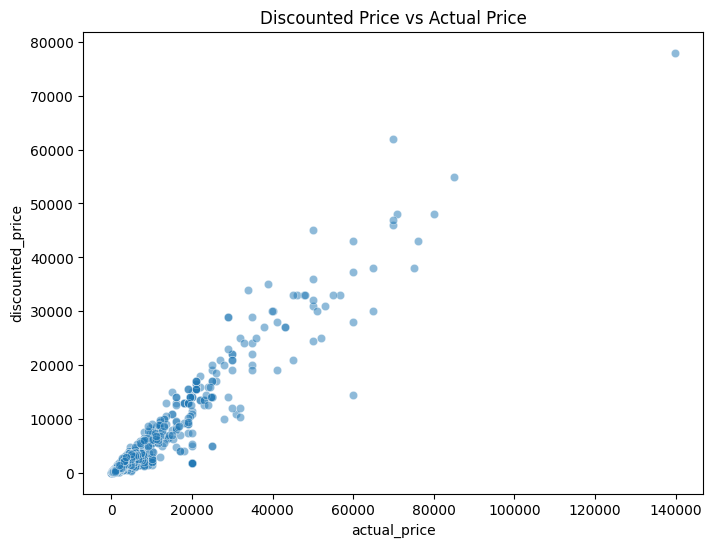

In [43]:
df_amazon['discounted_price'] = df_amazon['discounted_price'].str.replace('₹', '').str.replace(',', '').astype(float)
df_amazon['actual_price'] = df_amazon['actual_price'].str.replace('₹', '').str.replace(',', '').astype(float)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_amazon, x='actual_price', y='discounted_price', alpha=0.5)
plt.title('Discounted Price vs Actual Price')
plt.show()

### Q4. How does the average discount percentage vary across categories?

In [44]:
df_amazon['discount_percentage'] = df_amazon['discount_percentage'].str.replace('%', '').astype(float)
avg_disc_cat = df_amazon.groupby('category')['discount_percentage'].mean().reset_index()
print(avg_disc_cat)

                                              category  discount_percentage
0    Car&Motorbike|CarAccessories|InteriorAccessori...                 42.0
1    Computers&Accessories|Accessories&Peripherals|...                 78.5
2    Computers&Accessories|Accessories&Peripherals|...                 35.0
3    Computers&Accessories|Accessories&Peripherals|...                 56.5
4    Computers&Accessories|Accessories&Peripherals|...                 46.5
..                                                 ...                  ...
206  OfficeProducts|OfficePaperProducts|Paper|Stati...                  0.0
207  OfficeProducts|OfficePaperProducts|Paper|Stati...                  5.0
208  OfficeProducts|OfficePaperProducts|Paper|Stati...                 17.5
209  OfficeProducts|OfficePaperProducts|Paper|Stati...                 13.0
210  Toys&Games|Arts&Crafts|Drawing&PaintingSupplie...                  0.0

[211 rows x 2 columns]


### Q5. What are the most popular product names?

In [45]:
print(df_amazon['product_name'].value_counts().head(10))

product_name
Fire-Boltt Ninja Call Pro Plus 1.83" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sports Modes IP67 Rating, 240*280 Pixel High Resolution                                                  5
Fire-Boltt Phoenix Smart Watch with Bluetooth Calling 1.3",120+ Sports Modes, 240*240 PX High Res with SpO2, Heart Rate Monitoring & IP67 Rating                                                           4
Amazonbasics Nylon Braided Usb-C To Lightning Cable, Fast Charging Mfi Certified Smartphone, Iphone Charger (6-Foot, Dark Grey)                                                                            3
Duracell USB Lightning Apple Certified (Mfi) Braided Sync & Charge Cable For Iphone, Ipad And Ipod. Fast Charging Lightning Cable, 3.9 Feet (1.2M) - Black                                                 3
Flix Micro Usb Cable For Smartphone (Black)                                                                                                                            

Q6. What are the most popular product keywords ?

In [46]:
print(df_amazon['product_name'].value_counts().head(5))

product_name
Fire-Boltt Ninja Call Pro Plus 1.83" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sports Modes IP67 Rating, 240*280 Pixel High Resolution     5
Fire-Boltt Phoenix Smart Watch with Bluetooth Calling 1.3",120+ Sports Modes, 240*240 PX High Res with SpO2, Heart Rate Monitoring & IP67 Rating              4
Amazonbasics Nylon Braided Usb-C To Lightning Cable, Fast Charging Mfi Certified Smartphone, Iphone Charger (6-Foot, Dark Grey)                               3
Duracell USB Lightning Apple Certified (Mfi) Braided Sync & Charge Cable For Iphone, Ipad And Ipod. Fast Charging Lightning Cable, 3.9 Feet (1.2M) - Black    3
Flix Micro Usb Cable For Smartphone (Black)                                                                                                                   3
Name: count, dtype: int64


Q7. What are the most popular product reviews?


In [61]:
print(df_amazon['review_title'].value_counts().head(5))

review_title
Worked on iPhone 7 and didn’t work on XR,Good one,Dull Physical Looks,Just Buy it,Go for it,About the product,Get charging cable at the price,Working well.                                                                                                        10
Satisfied,Charging is really fast,Value for money,Product review,Good quality,Good product,Good Product,As of now seems good                                                                                                                                        8
Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent under this budget,Worth the price at 9499,Ok type phone... but unable to make videocall within same service provider.,Phone review,Budget king,Battery backup is good     8
A Good Braided Cable for Your Type C Device,Good quality product from ambrane,Super cable,As,Good quality,Good product,its good,Good quality for the price but one issue with my unit                    

### Q8. What is the correlation between discounted_price and rating?

In [63]:
print('Correlation:', df_amazon[['discounted_price', 'rating']].corr().iloc[0, 1])

Correlation: 0.12033741712288648


### Q9. What are the Top 5 categories based on highest ratings?

In [48]:
top_5_categories = df_amazon.groupby('category')['rating'].mean().reset_index().sort_values(by='rating', ascending=False).head(5)
print(top_5_categories)

                                             category  rating
57                      Computers&Accessories|Tablets     4.6
48  Computers&Accessories|NetworkingDevices|Networ...     4.5
62   Electronics|Cameras&Photography|Accessories|Film     4.5
38            Computers&Accessories|Components|Memory     4.5
81  Electronics|HomeAudio|MediaStreamingDevices|St...     4.5


Q10. Identify any potential areas for improvement or optimization based on the data analysis ?

 Focus on inventory of high-rating categories and review pricing strategies for heavily discounted items with low ratings.

---\n# EDA - 4: Spotify Data (Popular Hip-Hop Artists and Tracks)

In [49]:
# Load dataset
df_spotify = pd.read_csv('/content/spotify.csv')

### Q1. Read the dataframe, check null values and duplicate rows.

In [50]:
print('Null values:\n', df_spotify.isnull().sum())
df_spotify.dropna(inplace=True)

print('Duplicate rows count:', df_spotify.duplicated().sum())
df_spotify.drop_duplicates(inplace=True)

Null values:
 Artist           0
Track Name       0
Popularity       0
Duration (ms)    0
Track ID         0
dtype: int64
Duplicate rows count: 27


### Q2. What is the distribution of popularity among tracks? Visualize using a histogram.

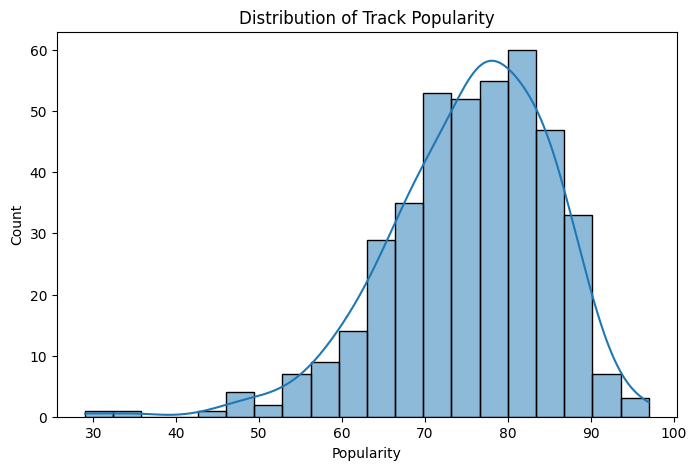

In [51]:
plt.figure(figsize=(8, 5))
sns.histplot(df_spotify['Popularity'], bins=20, kde=True)
plt.title('Distribution of Track Popularity')
plt.show()

### Q3. Is there any relationship between popularity and duration of tracks?

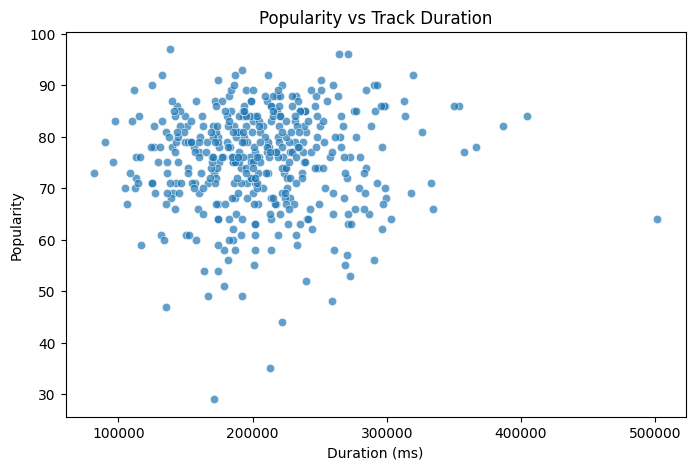

In [52]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_spotify, x='Duration (ms)', y='Popularity', alpha=0.7)
plt.title('Popularity vs Track Duration')
plt.show()

### Q4. Which artist has the highest number of tracks?

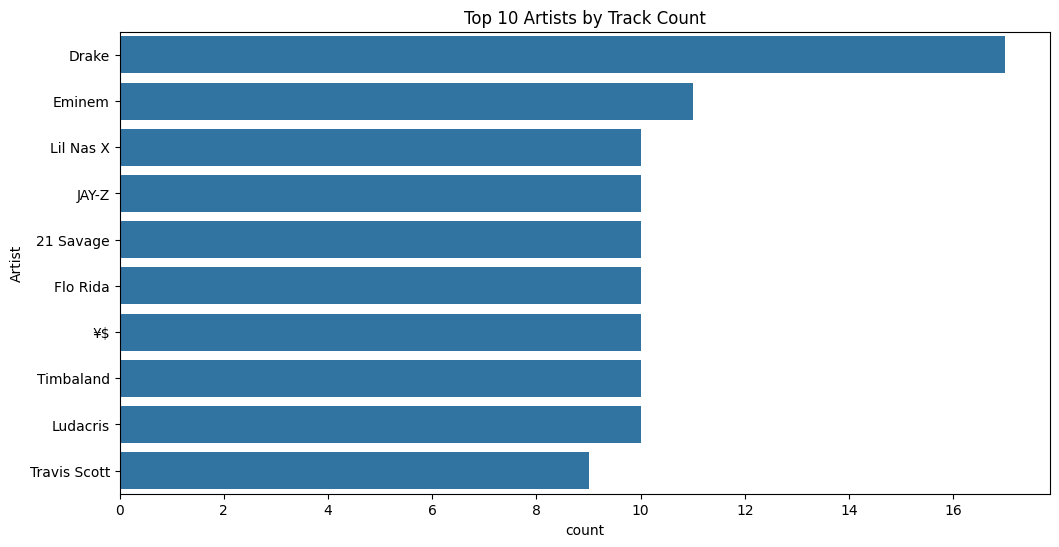

In [53]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_spotify, y='Artist', order=df_spotify['Artist'].value_counts().head(10).index)
plt.title('Top 10 Artists by Track Count')
plt.show()

### Q5. What are the top 5 least popular tracks in the dataset?

In [54]:
least_popular = df_spotify.sort_values(by='Popularity', ascending=True).head(5)
print(least_popular[['Artist', 'Track Name', 'Popularity']])

             Artist                     Track Name  Popularity
207          Pressa  Attachments (feat. Coi Leray)          29
231   Justin Bieber                     Intentions          35
413  French Montana                Splash Brothers          44
225        Lil Baby                  On Me - Remix          47
407     Wyclef Jean      911 (feat. Mary J. Blige)          48


### Q6. Among the top 5 most popular artists, which artist has the highest popularity on average?

In [55]:
top_5_artists = df_spotify['Artist'].value_counts().head(5).index
top_artists_df = df_spotify[df_spotify['Artist'].isin(top_5_artists)]
avg_pop_top5 = top_artists_df.groupby('Artist')['Popularity'].mean().reset_index()
print(avg_pop_top5.sort_values(by='Popularity', ascending=False))

      Artist  Popularity
0  21 Savage   83.800000
2     Eminem   83.636364
1      Drake   82.882353
3      JAY-Z   77.900000
4  Lil Nas X   75.900000


### Q7. For the top 5 most popular artists, what are their most popular tracks?

In [56]:
top_tracks = top_artists_df.sort_values(by=['Artist', 'Popularity'], ascending=[True, False]).groupby('Artist').head(1)
print(top_tracks[['Artist', 'Track Name', 'Popularity']])

        Artist                               Track Name  Popularity
70   21 Savage                                   redrum          96
0        Drake  Rich Baby Daddy (feat. Sexyy Red & SZA)          92
80      Eminem                               Without Me          90
100      JAY-Z                          Ni**as In Paris          86
312  Lil Nas X                        THATS WHAT I WANT          81


### Q8. Visualize relationships between multiple numerical variables simultaneously using a pair plot.

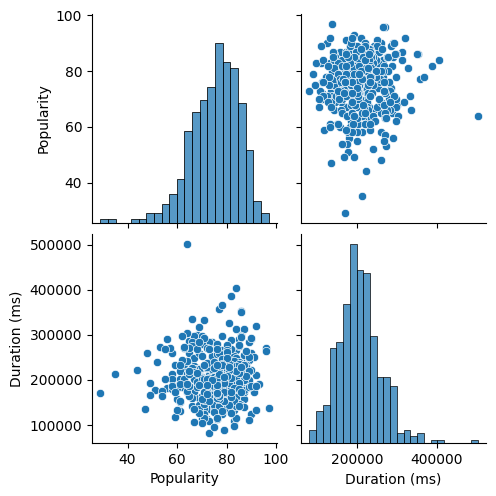

In [57]:
sns.pairplot(df_spotify.select_dtypes(include=[np.number]))
plt.show()

### Q9. Does the duration of tracks vary significantly across different artists?

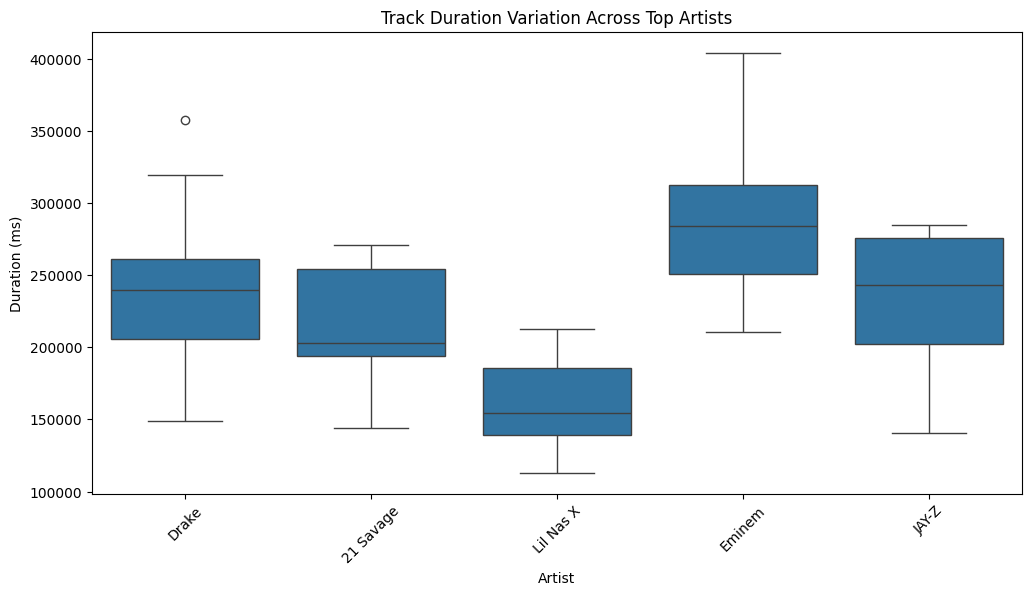

In [58]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=top_artists_df, x='Artist', y='Duration (ms)')
plt.xticks(rotation=45)
plt.title('Track Duration Variation Across Top Artists')
plt.show()

### Q10. How does the distribution of track popularity vary for different artists?

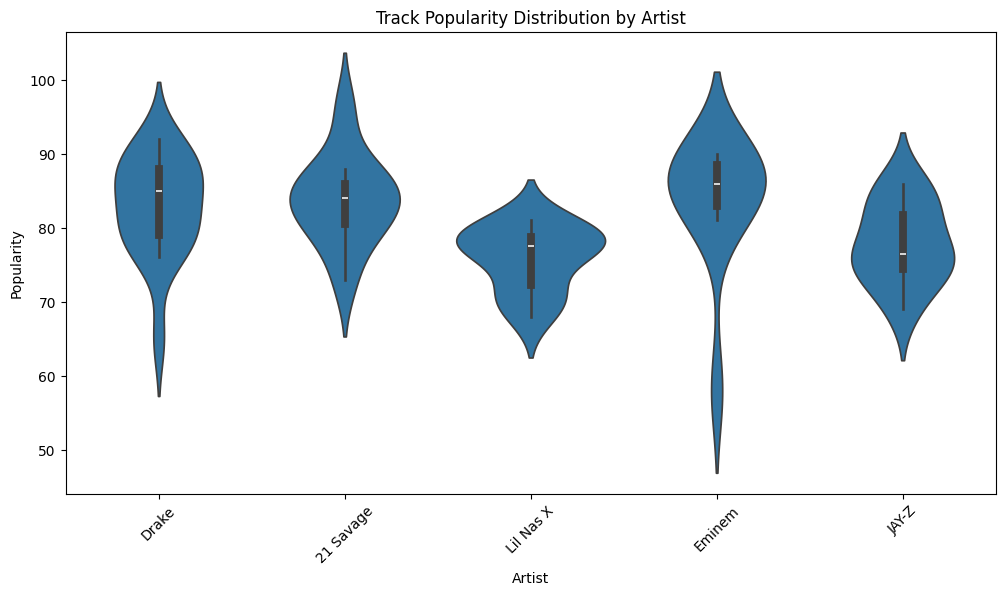

In [59]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=top_artists_df, x='Artist', y='Popularity')
plt.xticks(rotation=45)
plt.title('Track Popularity Distribution by Artist')
plt.show()